# IPL Matches Data — Detailed EDA and Cleaning

## Objective

This notebook investigates the supplied IPL matches dataset one question at a time. The sequence is intentional: understand the table, check its structure, investigate missingness and identifiers, validate match/toss/result logic, inspect patterns, make only defensible cleaning changes, and verify the exported file.

**Row grain:** one row is intended to represent one match.

**Scope:** single-file EDA and conservative cleaning. This notebook does not join team/player lookup tables, invent missing results, or certify facts that cannot be established from this file alone.

**Decision rule:** an unusual value is a reason to investigate, not automatically a reason to delete or replace it. Where a source-level question remains unresolved, the notebook records it and preserves the value.

## 1. Load the file and protect the raw source

First, load the uploaded CSV and keep an untouched copy. The input path below assumes the CSV is in the same folder as this notebook. If your files are elsewhere, update `DATA_PATH` explicitly.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("../../ipl_matches_data.csv")

OUTPUT_DIR = Path("../../data/cleaned")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_PATH = OUTPUT_DIR / "ipl_matches_data_clean.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Source CSV not found: {DATA_PATH.resolve()}"
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy(deep=True)

print(f"Loaded file: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Loaded file: C:\Users\Bhuvan\Desktop\IPL DATA\ipl_matches_data.csv
Rows: 1,212
Columns: 23
Memory usage: 0.32 MB


### Initial question: what does one record look like?

A few records from the start and end help confirm that the file parsed as expected. This is a quick visual check, not a substitute for systematic validation.

In [6]:
display(df.head())
display(df.tail(3))
print("Column names:")
print(df.columns.tolist())

,match_id,season_id,balls_per_over,city,match_date,event_name,match_number,gender,match_type,format,...,venue,toss_winner,team1,team2,toss_decision,match_winner,win_by_runs,win_by_wickets,result,player_of_match
0,335982,2008,6,Bangalore,2008-04-18,Indian Premier League,1.0,male,T20,T20,...,M Chinnaswamy Stadium,1,1,6,field,6,140.0,NaN,win,46.0
1,1082591,2017,6,Hyderabad,2017-04-05,Indian Premier League,1.0,male,T20,T20,...,"Rajiv Gandhi International Stadium, Uppal",1,2,1,field,2,35.0,NaN,win,15.0
2,1082592,2017,6,Pune,2017-04-06,Indian Premier League,2.0,male,T20,T20,...,Maharashtra Cricket Association Stadium,4,4,3,field,4,NaN,7.0,win,36.0
3,1082593,2017,6,Rajkot,2017-04-07,Indian Premier League,3.0,male,T20,T20,...,Saurashtra Cricket Association Stadium,6,5,6,field,6,NaN,10.0,win,57.0
4,1082594,2017,6,Indore,2017-04-08,Indian Premier League,4.0,male,T20,T20,...,Holkar Cricket Stadium,494,494,4,field,494,NaN,6.0,win,71.0


,match_id,season_id,balls_per_over,city,match_date,event_name,match_number,gender,match_type,format,...,venue,toss_winner,team1,team2,toss_decision,match_winner,win_by_runs,win_by_wickets,result,player_of_match
1209,1529284,2026,6,Mumbai,2026-04-29,Indian Premier League,41.0,male,T20,T20,...,"Wankhede Stadium, Mumbai",3,3,2,bat,2,NaN,6.0,win,1740.0
1210,1529285,2026,6,Ahmedabad,2026-04-30,Indian Premier League,42.0,male,T20,T20,...,"Narendra Modi Stadium, Ahmedabad",615,1,615,field,615,NaN,4.0,win,4098.0
1211,1529286,2026,6,Jaipur,2026-05-01,Indian Premier League,43.0,male,T20,T20,...,"Sawai Mansingh Stadium, Jaipur",134,134,252,bat,252,NaN,7.0,win,1409.0


Column names:
['match_id', 'season_id', 'balls_per_over', 'city', 'match_date', 'event_name', 'match_number', 'gender', 'match_type', 'format', 'overs', 'season', 'team_type', 'venue', 'toss_winner', 'team1', 'team2', 'toss_decision', 'match_winner', 'win_by_runs', 'win_by_wickets', 'result', 'player_of_match']


## 2. Understand the schema and overall quality

Before investigating individual fields, establish data types, missing-value counts, unique-value counts, and summary statistics. This baseline will help us decide which columns need attention.

In [7]:
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_missing": df.nunique(dropna=True)
})
display(structure)

,dtype,non_missing,missing,missing_pct,unique_non_missing
match_id,int64,1212,0,0.00,1212
season_id,int64,1212,0,0.00,19
balls_per_over,int64,1212,0,0.00,1
city,str,1161,51,4.21,37
match_date,str,1212,0,0.00,920
event_name,str,1212,0,0.00,1
match_number,float64,1142,70,5.78,72
gender,str,1212,0,0.00,1
match_type,str,1212,0,0.00,1
format,str,1212,0,0.00,1


In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,1212.0,NaN,NaN,NaN,961685.974422,390532.810455,335982.0,548362.75,1082620.5,1304079.25,1529286.0
season_id,1212.0,NaN,NaN,NaN,2017.018152,5.439222,2008.0,2012.0,2017.0,2022.0,2026.0
balls_per_over,1212.0,NaN,NaN,NaN,6.0,0.0,6.0,6.0,6.0,6.0,6.0
city,1161,37,Mumbai,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match_date,1212,920,2017-04-08,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,1212,1,Indian Premier League,1212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match_number,1142.0,NaN,NaN,NaN,31.328371,18.397497,1.0,16.0,31.0,46.0,72.0
gender,1212,1,male,1212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match_type,1212,1,T20,1212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
format,1212,1,T20,1212,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_pct
win_by_runs,666,54.95
win_by_wickets,571,47.11
match_number,70,5.78
city,51,4.21
player_of_match,9,0.74


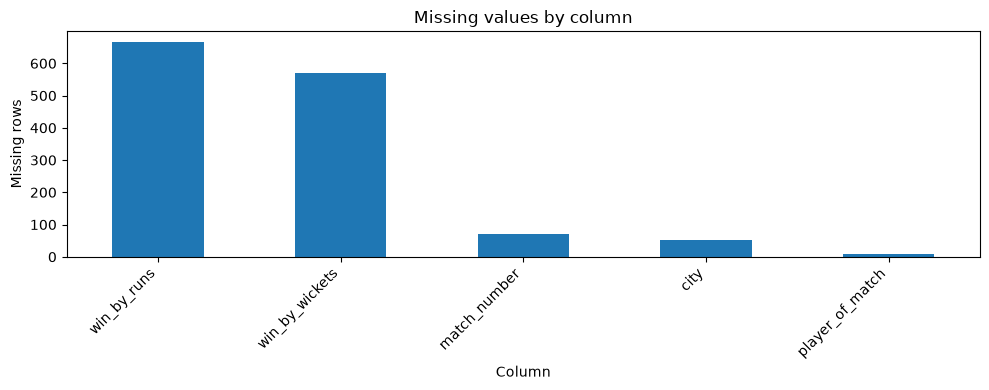

In [9]:
missing_summary = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

if not missing_summary.empty:
    ax = missing_summary["missing_count"].plot(
        kind="bar", figsize=(10, 4), title="Missing values by column"
    )
    ax.set_xlabel("Column")
    ax.set_ylabel("Missing rows")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 3. Establish the table's grain and identifier quality

If each row represents a match, `match_id` should identify a single row. We check exact duplicates separately from duplicate IDs: identical rows and repeated identifiers are different problems. We also inspect whether a match ID is associated with more than one season.

In [10]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Missing match_id values: {df['match_id'].isna().sum():,}")
print(f"Duplicate match_id values: {df['match_id'].duplicated().sum():,}")
print(f"Unique match_id values: {df['match_id'].nunique(dropna=True):,}")
print(f"match_id range: {df['match_id'].min()} to {df['match_id'].max()}")

if df["match_id"].duplicated().any():
    display(df[df["match_id"].duplicated(keep=False)].sort_values("match_id").head(30))

Exact duplicate rows: 0
Missing match_id values: 0
Duplicate match_id values: 0
Unique match_id values: 1,212
match_id range: 335982 to 1529286


In [11]:
match_season_counts = df.groupby("match_id", dropna=False)["season_id"].nunique(dropna=False)
cross_season_match_ids = match_season_counts[match_season_counts > 1]
print(f"Match IDs associated with multiple season_id values: {len(cross_season_match_ids):,}")
if len(cross_season_match_ids):
    display(cross_season_match_ids.rename("season_count").to_frame())

Match IDs associated with multiple season_id values: 0


## 4. Check dates and season coverage

The source stores `match_date` as text, so parse it into a temporary datetime series to check whether every value is valid. Then review the date range and number of matches per season. The season labels are retained as supplied; for example, a season label such as `2020/21` may differ from its numeric `season_id`.

The latest season may be incomplete. Counts should not be compared as if every season had equal coverage without confirming that coverage independently.

In [12]:
parsed_dates = pd.to_datetime(df["match_date"], errors="coerce")
date_parse_failures = int(parsed_dates.isna().sum())
print(f"Date parse failures: {date_parse_failures:,}")
if parsed_dates.notna().any():
    print(f"Date range: {parsed_dates.min().date()} to {parsed_dates.max().date()}")

invalid_date_rows = df.loc[parsed_dates.isna(), ["match_id", "season_id", "match_date"]]
if len(invalid_date_rows):
    display(invalid_date_rows.head(20))

Date parse failures: 0
Date range: 2008-04-18 to 2026-05-01


In [13]:
season_summary = df.groupby(["season_id", "season"], dropna=False).agg(
    match_rows=("match_id", "size"),
    unique_match_ids=("match_id", "nunique"),
    first_date=("match_date", "min"),
    last_date=("match_date", "max")
).reset_index().sort_values(["season_id", "season"])
display(season_summary)

,season_id,season,match_rows,unique_match_ids,first_date,last_date
0,2008,2008,58,58,2008-04-18,2008-06-01
1,2009,2009,57,57,2009-04-18,2009-05-24
2,2010,2010,60,60,2010-03-12,2010-04-25
3,2011,2011,73,73,2011-04-08,2011-05-28
4,2012,2012,74,74,2012-04-04,2012-05-27
5,2013,2013,76,76,2013-04-03,2013-05-26
6,2014,2014,60,60,2014-04-16,2014-06-01
7,2015,2015,59,59,2015-04-08,2015-05-24
8,2016,2016,60,60,2016-04-09,2016-05-29
9,2017,2017,59,59,2017-04-05,2017-05-21


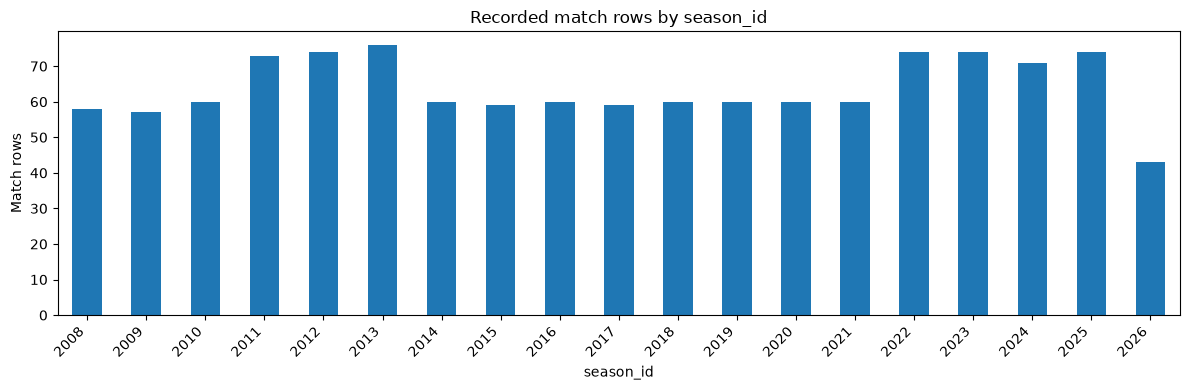

In [14]:
plot_season = df.groupby("season_id").agg(
    match_rows=("match_id", "size"),
    first_date=("match_date", "min"),
    last_date=("match_date", "max")
).sort_index()

ax = plot_season["match_rows"].plot(
    kind="bar", figsize=(12, 4), title="Recorded match rows by season_id"
)
ax.set_xlabel("season_id")
ax.set_ylabel("Match rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Investigate missing city values

There are missing values in `city`, but a missing city does not necessarily mean the venue is missing. First inspect the venues associated with missing city values. If all missing-city rows belong to known venues whose city is explicit in the venue name, we can apply a small, documented mapping. If a venue cannot be mapped confidently, its city should remain missing.

In [15]:
missing_city_rows = df.loc[df["city"].isna(), ["match_id", "season_id", "match_date", "venue"]]
print(f"Rows with missing city: {len(missing_city_rows):,}")
display(missing_city_rows["venue"].value_counts(dropna=False).to_frame("rows"))
display(missing_city_rows.head(20))

Rows with missing city: 51


,rows
venue,
Dubai International Cricket Stadium,33
Sharjah Cricket Stadium,18


,match_id,season_id,match_date,venue
181,1216493,2020,2020-09-20,Dubai International Cricket Stadium
183,1216495,2020,2020-11-03,Sharjah Cricket Stadium
184,1216496,2020,2020-09-22,Sharjah Cricket Stadium
186,1216498,2020,2020-10-24,Dubai International Cricket Stadium
188,1216500,2020,2020-10-09,Sharjah Cricket Stadium
190,1216502,2020,2020-10-31,Sharjah Cricket Stadium
192,1216504,2020,2020-09-30,Dubai International Cricket Stadium
195,1216507,2020,2020-10-11,Dubai International Cricket Stadium
197,1216509,2020,2020-10-17,Sharjah Cricket Stadium
198,1216510,2020,2020-09-24,Dubai International Cricket Stadium


**Cleaning decision:** in this file, missing city values occur at `Dubai International Cricket Stadium` and `Sharjah Cricket Stadium`. These venue names identify the city unambiguously, so the cleaning step will fill those two exact venue-to-city mappings. This is an explicit inference from the venue field, not a general rule to guess cities from arbitrary venue names.

In [16]:
city_venue_mapping = {
    "Dubai International Cricket Stadium": "Dubai",
    "Sharjah Cricket Stadium": "Sharjah"
}

## 6. Inspect venues and text consistency

Text columns may contain leading/trailing spaces or strings that look blank but are not null. These can create duplicate categories in a dashboard. Count these cases before normalizing them.

In [17]:
text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
text_quality = []
for col in text_columns:
    s = df[col].astype("string")
    non_missing = s.notna()
    text_quality.append({
        "column": col,
        "non_missing": int(non_missing.sum()),
        "leading_trailing_whitespace": int((non_missing & s.ne(s.str.strip())).sum()),
        "whitespace_only": int((non_missing & s.str.strip().eq("")).sum()),
        "distinct_values": int(df[col].nunique(dropna=True))
    })
display(pd.DataFrame(text_quality).set_index("column"))

,non_missing,leading_trailing_whitespace,whitespace_only,distinct_values
column,,,,
city,1161,0,0,37
match_date,1212,0,0,920
event_name,1212,0,0,1
gender,1212,0,0,1
match_type,1212,0,0,1
format,1212,0,0,1
season,1212,0,0,19
team_type,1212,0,0,1
venue,1212,0,0,59


In [18]:
print(f"Unique venues: {df['venue'].nunique(dropna=True)}")
print("Most frequent venues:")
display(df["venue"].value_counts(dropna=False).head(15).to_frame("match_rows"))

print("City distribution, including missing:")
display(df["city"].value_counts(dropna=False).head(20).to_frame("match_rows"))

Unique venues: 59
Most frequent venues:


,match_rows
venue,
Eden Gardens,77
Wankhede Stadium,73
M Chinnaswamy Stadium,65
Feroz Shah Kotla,60
"Wankhede Stadium, Mumbai",57
"Rajiv Gandhi International Stadium, Uppal",49
"MA Chidambaram Stadium, Chepauk",48
Sawai Mansingh Stadium,47
Dubai International Cricket Stadium,46


City distribution, including missing:


,match_rows
city,
Mumbai,185
Kolkata,104
Delhi,101
Chennai,95
Hyderabad,87
Jaipur,66
Bangalore,65
Chandigarh,61
Pune,51


## 7. Identify constant columns

A column with one non-missing value has no variation in this particular file, so it cannot distinguish matches in current analyses. We report these columns, but do not drop them automatically: they may still be part of the source schema or useful if the dataset is later extended.

In [19]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=True) <= 1
]
print("Columns with one or fewer distinct non-missing values:")
print(constant_columns)

constant_report = pd.DataFrame({
    "column": constant_columns,
    "distinct_non_missing": [df[c].nunique(dropna=True) for c in constant_columns],
    "only_value": [
        df[c].dropna().iloc[0] if df[c].notna().any() else pd.NA
        for c in constant_columns
    ]
})
display(constant_report)

Columns with one or fewer distinct non-missing values:
['balls_per_over', 'event_name', 'gender', 'match_type', 'format', 'overs', 'team_type']


,column,distinct_non_missing,only_value
0,balls_per_over,1,6
1,event_name,1,Indian Premier League
2,gender,1,male
3,match_type,1,T20
4,format,1,T20
5,overs,1,20
6,team_type,1,club


## 8. Validate match teams and toss consistency

The team columns contain numeric IDs, not human-readable franchise names. We can still test internal relationships: `team1` and `team2` should differ, and `toss_winner` should be one of those two teams. We should not assign franchise names without a reliable lookup table.

In [20]:
same_team_rows = df["team1"].eq(df["team2"])
valid_toss_winner = df.apply(
    lambda row: row["toss_winner"] in [row["team1"], row["team2"]], axis=1
)
print("Rows where team1 equals team2:", int(same_team_rows.sum()))
print("Rows where toss_winner is not team1 or team2:", int((~valid_toss_winner).sum()))

for col in ["team1", "team2", "toss_winner"]:
    print(f"{col}: {df[col].nunique(dropna=True)} unique IDs")

print("Toss decision distribution:")
display(df["toss_decision"].value_counts(dropna=False).to_frame("match_rows"))

Rows where team1 equals team2: 0
Rows where toss_winner is not team1 or team2: 0
team1: 14 unique IDs
team2: 14 unique IDs
toss_winner: 14 unique IDs
Toss decision distribution:


,match_rows
toss_decision,
field,800
bat,412


In [21]:
invalid_toss_rows = df.loc[
    ~valid_toss_winner,
    ["match_id", "team1", "team2", "toss_winner", "toss_decision"]
]
if len(invalid_toss_rows):
    display(invalid_toss_rows.head(20))

## 9. Validate match winners and result labels

For rows whose `result` is `win`, the winner should be either `team1` or `team2`. Tied and no-result matches can have different winner semantics, so they should be inspected separately rather than forced into the same rule.

In [22]:
print("Result distribution:")
display(df["result"].value_counts(dropna=False).to_frame("match_rows"))

win_rows = df[df["result"].eq("win")]
invalid_winner_rows = win_rows[
    ~win_rows.apply(
        lambda row: row["match_winner"] in [row["team1"], row["team2"]], axis=1
    )
]
print(f"Win rows: {len(win_rows):,}")
print(f"Win rows where match_winner is not team1/team2: {len(invalid_winner_rows):,}")
if len(invalid_winner_rows):
    display(invalid_winner_rows[["match_id", "team1", "team2", "match_winner", "result"]])

Result distribution:


,match_rows
result,
win,1187
tie,16
no result,9


Win rows: 1,187
Win rows where match_winner is not team1/team2: 0


## 10. Validate winning margins

For a decisive win, this file should have one winning margin populated: runs or wickets. Ties and no-result matches should not carry either margin. These are internal consistency rules for the supplied schema; unusual cases should be inspected rather than repaired automatically.

In [23]:
both_margins = win_rows["win_by_runs"].notna() & win_rows["win_by_wickets"].notna()
neither_margin = win_rows["win_by_runs"].isna() & win_rows["win_by_wickets"].isna()
print(f"Win rows with both margins populated: {int(both_margins.sum()):,}")
print(f"Win rows with neither margin populated: {int(neither_margin.sum()):,}")

tie_or_no_result = df[df["result"].isin(["tie", "no result"])]
tie_nr_with_margin = tie_or_no_result[
    tie_or_no_result["win_by_runs"].notna() | tie_or_no_result["win_by_wickets"].notna()
]
print(f"Tie/no-result rows with a margin populated: {len(tie_nr_with_margin):,}")
if len(tie_nr_with_margin):
    display(tie_nr_with_margin[
        ["match_id", "result", "win_by_runs", "win_by_wickets"]
    ])

Win rows with both margins populated: 0
Win rows with neither margin populated: 0
Tie/no-result rows with a margin populated: 0


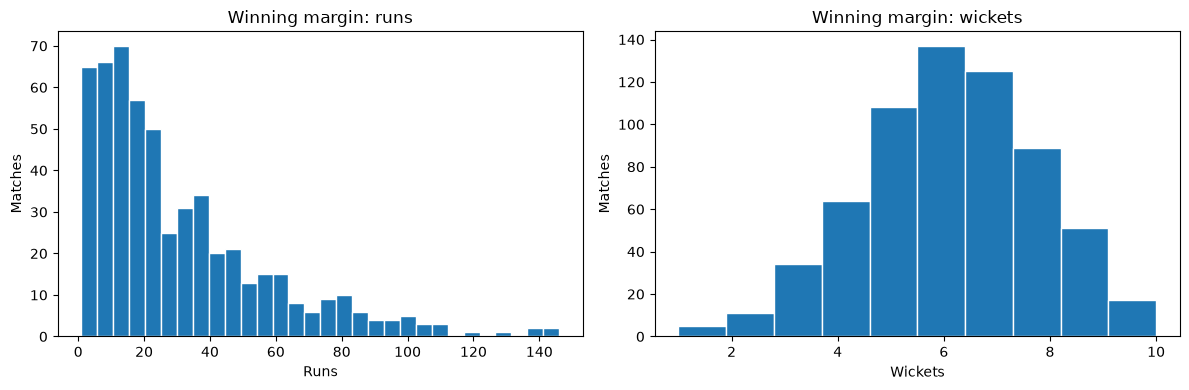

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

runs_margin = win_rows["win_by_runs"].dropna()
wickets_margin = win_rows["win_by_wickets"].dropna()

axes[0].hist(runs_margin, bins=30, edgecolor="white")
axes[0].set_title("Winning margin: runs")
axes[0].set_xlabel("Runs")
axes[0].set_ylabel("Matches")

axes[1].hist(wickets_margin, bins=10, edgecolor="white")
axes[1].set_title("Winning margin: wickets")
axes[1].set_xlabel("Wickets")
axes[1].set_ylabel("Matches")

plt.tight_layout()
plt.show()

## 11. Investigate player of the match and match numbering

Missing `player_of_match` values should be compared with match results. Missing awards on no-result matches may be structurally expected; if any other result categories have missing awards, inspect them rather than assuming the cause.

`match_number` can be absent for special fixtures or due to source conventions. We will report its distribution by season but will not invent match numbers.

In [25]:
print(f"Missing player_of_match: {df['player_of_match'].isna().sum():,}")
display(
    df.loc[df["player_of_match"].isna(), "result"]
    .value_counts(dropna=False)
    .rename_axis("result")
    .to_frame("missing_award_rows")
)

print(f"Missing match_number: {df['match_number'].isna().sum():,}")
display(
    df.loc[df["match_number"].isna()]
    .groupby(["season_id", "season"], dropna=False)
    .size()
    .rename("missing_match_number_rows")
    .to_frame()
)

Missing player_of_match: 9


,missing_award_rows
result,
no result,9


Missing match_number: 70


,,missing_match_number_rows
season_id,season,
2008,2008,3
2009,2009,3
2010,2010,4
2011,2011,4
2012,2012,4
2013,2013,4
2014,2014,4
2015,2015,4
2016,2016,4


In [26]:
match_number_summary = df.groupby("season_id").agg(
    match_rows=("match_id", "size"),
    missing_match_number=("match_number", lambda s: s.isna().sum()),
    distinct_match_numbers=("match_number", "nunique")
).sort_index()
display(match_number_summary)

,match_rows,missing_match_number,distinct_match_numbers
season_id,,,
2008,58,3,55
2009,57,3,54
2010,60,4,56
2011,73,4,69
2012,74,4,70
2013,76,4,72
2014,60,4,56
2015,59,4,55
2016,60,4,56


## 12. Review event and season labels

Season labels and event labels provide useful context but may not be interchangeable with numeric season IDs. We inspect the values and keep both source fields rather than replacing one with the other.

In [27]:
print("Event name values:")
display(df["event_name"].value_counts(dropna=False).to_frame("rows"))

season_label_check = (
    df.groupby(["season_id", "season"], dropna=False)
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(["season_id", "season"])
)
display(season_label_check)

Event name values:


,rows
event_name,
Indian Premier League,1212


,season_id,season,rows
0,2008,2008,58
1,2009,2009,57
2,2010,2010,60
3,2011,2011,73
4,2012,2012,74
5,2013,2013,76
6,2014,2014,60
7,2015,2015,59
8,2016,2016,60
9,2017,2017,59


## 13. Make cleaning decisions

The data checks support a conservative cleaning policy:

1. Strip leading/trailing whitespace from text columns.
2. Convert whitespace-only text to proper missing values.
3. Fill city only for the two exact venue mappings investigated above.
4. Parse and validate `match_date`, then store it as a consistent ISO `YYYY-MM-DD` string for CSV interoperability.
5. Retain legitimate missing margins, `match_number`, and `player_of_match` values.
6. Keep constant columns and all match rows; do not remove records merely because a field is missing.
7. Do not change numeric IDs or infer team names without a lookup source.

In [28]:
df_clean = df_raw.copy(deep=True)

# Normalize text without changing the meaning of non-blank values.
clean_text_columns = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()
for col in clean_text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

# Apply only the exact venue-to-city mappings observed in the missing-city investigation.
city_was_missing = df_clean["city"].isna()
for venue_name, city_name in city_venue_mapping.items():
    mask = city_was_missing & df_clean["venue"].eq(venue_name)
    df_clean.loc[mask, "city"] = city_name

# Parse dates and export them in a consistent ISO date format.
clean_dates = pd.to_datetime(df_clean["match_date"], errors="coerce")
if clean_dates.isna().any():
    raise ValueError("At least one match_date could not be parsed; inspect these rows before export.")
df_clean["match_date"] = clean_dates.dt.strftime("%Y-%m-%d")

print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)
print("City values filled from exact venue mapping:", int(city_was_missing.sum() - df_clean["city"].isna().sum()))
print("Remaining missing city values:", int(df_clean["city"].isna().sum()))
print("Rows removed:", len(df_raw) - len(df_clean))

Original shape: (1212, 23)
Cleaned shape: (1212, 23)
City values filled from exact venue mapping: 51
Remaining missing city values: 0
Rows removed: 0


## 14. Final validation

Now repeat the key checks on the cleaned dataset. These checks confirm that cleaning did not change the number of match records or break the relationships examined above. Passing them is not proof that every source-level fact is correct; the remaining caveats are listed afterward.

In [29]:
final_checks = {
    "row_count_unchanged": len(df_clean) == len(df_raw),
    "column_count_unchanged": df_clean.shape[1] == df_raw.shape[1],
    "match_id_has_no_missing_values": bool(df_clean["match_id"].notna().all()),
    "match_id_is_unique": bool(df_clean["match_id"].is_unique),
    "no_exact_duplicate_rows": int(df_clean.duplicated().sum()) == 0,
    "all_dates_parse": bool(pd.to_datetime(df_clean["match_date"], errors="coerce").notna().all()),
    "no_same_team_matchup": bool((df_clean["team1"] != df_clean["team2"]).all()),
    "toss_winner_is_one_of_the_teams": bool(
        df_clean.apply(lambda row: row["toss_winner"] in [row["team1"], row["team2"]], axis=1).all()
    ),
    "winner_valid_for_decisive_wins": bool(
        df_clean.loc[df_clean["result"].eq("win")].apply(
            lambda row: row["match_winner"] in [row["team1"], row["team2"]], axis=1
        ).all()
    ),
    "win_margin_columns_mutually_exclusive": bool(
        not (
            df_clean.loc[df_clean["result"].eq("win"), "win_by_runs"].notna()
            & df_clean.loc[df_clean["result"].eq("win"), "win_by_wickets"].notna()
        ).any()
        and not (
            df_clean.loc[df_clean["result"].eq("win"), "win_by_runs"].isna()
            & df_clean.loc[df_clean["result"].eq("win"), "win_by_wickets"].isna()
        ).any()
    ),
    "no_margins_for_tie_or_no_result": bool(
        not (
            df_clean.loc[df_clean["result"].isin(["tie", "no result"]), ["win_by_runs", "win_by_wickets"]]
            .notna().any(axis=1)
        ).any()
    ),
    "no_leading_trailing_whitespace": bool(all(
        not (
            df_clean[col].dropna().astype("string")
            .ne(df_clean[col].dropna().astype("string").str.strip())
        ).any()
        for col in clean_text_columns
    ))
}
validation = pd.DataFrame({"passed": pd.Series(final_checks)})
display(validation)
print(f"Checks passed: {sum(final_checks.values())}/{len(final_checks)}")
failed_checks = [name for name, passed in final_checks.items() if not passed]
if failed_checks:
    print("Checks requiring attention:", failed_checks)

,passed
row_count_unchanged,True
column_count_unchanged,True
match_id_has_no_missing_values,True
match_id_is_unique,True
no_exact_duplicate_rows,True
all_dates_parse,True
no_same_team_matchup,True
toss_winner_is_one_of_the_teams,True
winner_valid_for_decisive_wins,True
win_margin_columns_mutually_exclusive,True


Checks passed: 12/12


## 15. Document remaining caveats

The purpose of this register is to distinguish what the file demonstrates from what still needs an external source or domain confirmation. These caveats do not automatically block a general match-summary dashboard, but they matter for the relevant analyses.

In [30]:
issue_register = pd.DataFrame([
    {
        "topic": "team and player IDs",
        "observed_evidence": "The dataset stores team and player references as numeric IDs.",
        "decision": "Preserve IDs as supplied.",
        "caveat_or_follow_up": "Use a trusted lookup table before displaying franchise/player names."
    },
    {
        "topic": "match_number",
        "observed_evidence": f"{int(df_clean['match_number'].isna().sum())} missing values remain.",
        "decision": "Do not infer match numbers.",
        "caveat_or_follow_up": "Confirm the source convention if match-number ordering is needed."
    },
    {
        "topic": "player_of_match",
        "observed_evidence": f"{int(df_clean['player_of_match'].isna().sum())} missing values; compare their result categories in Section 11.",
        "decision": "Retain missing awards.",
        "caveat_or_follow_up": "Do not treat missing award as a player or match data error without source evidence."
    },
    {
        "topic": "season completeness",
        "observed_evidence": f"Season IDs span {df_clean['season_id'].min()} to {df_clean['season_id'].max()}; latest season has {int((df_clean['season_id'] == df_clean['season_id'].max()).sum())} rows.",
        "decision": "Keep all supplied rows.",
        "caveat_or_follow_up": "Confirm whether the latest season is complete before comparing season totals."
    },
    {
        "topic": "city inference",
        "observed_evidence": "Missing city values were associated with two venue names mapped explicitly in Section 5.",
        "decision": "Fill only those exact mappings.",
        "caveat_or_follow_up": "Review any new venue names with missing city separately rather than extending the mapping automatically."
    }
])
display(issue_register)

,topic,observed_evidence,decision,caveat_or_follow_up
0,team and player IDs,The dataset stores team and player references ...,Preserve IDs as supplied.,Use a trusted lookup table before displaying f...
1,match_number,70 missing values remain.,Do not infer match numbers.,Confirm the source convention if match-number ...
2,player_of_match,9 missing values; compare their result categor...,Retain missing awards.,Do not treat missing award as a player or matc...
3,season completeness,Season IDs span 2008 to 2026; latest season ha...,Keep all supplied rows.,Confirm whether the latest season is complete ...
4,city inference,Missing city values were associated with two v...,Fill only those exact mappings.,Review any new venue names with missing city s...


## 16. Export the cleaned CSV

This is the export step requested for downstream use. The file is written without a pandas index. The original 23-column schema and row count are preserved, while text normalization, the documented city mapping, and date standardization are applied. The exported file is reloaded immediately so its dimensions and column order can be checked.

In [31]:
if failed_checks:
    raise AssertionError(f"Export stopped because final validation failed: {failed_checks}")

df_clean.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

print(f"Cleaned CSV exported to: {OUTPUT_PATH.resolve()}")
print(f"Rows exported: {len(df_clean):,}")
print(f"Columns exported: {df_clean.shape[1]}")
print(f"File size: {OUTPUT_PATH.stat().st_size / (1024 ** 2):.2f} MB")

Cleaned CSV exported to: C:\Users\Bhuvan\Desktop\IPL DATA\data\cleaned\ipl_matches_data_clean.csv
Rows exported: 1,212
Columns exported: 23
File size: 0.18 MB


In [32]:
df_export_check = pd.read_csv(OUTPUT_PATH)
export_shape_matches = df_export_check.shape == df_clean.shape
export_columns_match = df_export_check.columns.tolist() == df_clean.columns.tolist()

print("Reloaded exported shape:", df_export_check.shape)
print("Shape matches cleaned dataframe:", export_shape_matches)
print("Column order matches cleaned dataframe:", export_columns_match)

assert export_shape_matches
assert export_columns_match
display(df_export_check.head(5))

Reloaded exported shape: (1212, 23)
Shape matches cleaned dataframe: True
Column order matches cleaned dataframe: True


,match_id,season_id,balls_per_over,city,match_date,event_name,match_number,gender,match_type,format,...,venue,toss_winner,team1,team2,toss_decision,match_winner,win_by_runs,win_by_wickets,result,player_of_match
0,335982,2008,6,Bangalore,2008-04-18,Indian Premier League,1.0,male,T20,T20,...,M Chinnaswamy Stadium,1,1,6,field,6,140.0,NaN,win,46.0
1,1082591,2017,6,Hyderabad,2017-04-05,Indian Premier League,1.0,male,T20,T20,...,"Rajiv Gandhi International Stadium, Uppal",1,2,1,field,2,35.0,NaN,win,15.0
2,1082592,2017,6,Pune,2017-04-06,Indian Premier League,2.0,male,T20,T20,...,Maharashtra Cricket Association Stadium,4,4,3,field,4,NaN,7.0,win,36.0
3,1082593,2017,6,Rajkot,2017-04-07,Indian Premier League,3.0,male,T20,T20,...,Saurashtra Cricket Association Stadium,6,5,6,field,6,NaN,10.0,win,57.0
4,1082594,2017,6,Indore,2017-04-08,Indian Premier League,4.0,male,T20,T20,...,Holkar Cricket Stadium,494,494,4,field,494,NaN,6.0,win,71.0
